# SmartSpec: Smartphone Price Prediction & Budget-Aware Recommendation
### INT315 — Cluster Computing | Apache Spark + PySpark MLlib | Google Colab

**Project goal.** Use Apache Spark DataFrames and Spark SQL to inspect and prepare a smartphone catalogue, train an actual **Spark MLlib regression model** to estimate a price from phone specifications, evaluate it with MAE/RMSE/R², and rank catalogue phones against a user's requirements and budget.

This notebook replaces the earlier scikit-learn modelling path. **The data cleaning, feature preparation, train/test split, model fitting, prediction, and regression evaluation are Spark-based.** A small numeric result subset may be collected for visualization only. The notebook also includes an RDD demonstration and attempts a real Scala GraphX demonstration if the installed Spark distribution provides `spark-shell` and GraphX.

> **Colab note:** The notebook uses Spark `local[*]` mode. That means Spark runs locally on the Colab VM; it is not a multi-node cluster. It still demonstrates Spark APIs and MLlib workflows required by the course.

## How to run this notebook
1. Open this `.ipynb` file in Google Colab.
2. Select **Runtime → Run all** (or execute each cell from top to bottom).
3. The setup cell installs PySpark and ensures Java 17+ is available.
4. When prompted, upload `Global_Mobile_Phone_Specifications_and_Prices_2026.csv` (the file with `(1)` or `(2)` in the name is also fine).
5. Read the detected schema/cleaning summaries, then review the genuine MLlib metrics and example recommendations at the end.
6. Capture your own Colab screenshots for the report after the cells have run successfully.

**Data caution:** the source `Price` field has values such as `৳18,999` and `Coming soon`. The notebook retains the source's numeric scale and does not convert currencies. The `৳` symbol suggests BDT, but verify the dataset's source, currency and license before submitting.

### Syllabus alignment
- **CO4:** Spark MLlib regression model and MAE/RMSE/R² evaluation.
- **CO5:** Spark DataFrame workflow and Spark SQL queries; RDD transformations/actions.
- **CO6:** A separate genuine Scala GraphX mini-demo is attempted near the end when compatible Spark shell support is available. The notebook will explicitly report if the runtime cannot execute it rather than claiming it succeeded.

In [ ]:
# Environment setup for Google Colab / Jupyter.
# Spark 4.x requires Java 17 or later. Keep a working Java 17/21 runtime if present;
# install Java 17 only if the current runtime is missing Java or is too old.
import os, sys, re, glob, shutil, subprocess, time, json, textwrap, tempfile
from pathlib import Path


def detected_java_major():
    java_exe = shutil.which("java")
    if not java_exe:
        return None, None
    result = subprocess.run([java_exe, "-version"], capture_output=True, text=True)
    output = (result.stderr or "") + (result.stdout or "")
    match = re.search(r'version "(\d+)', output)
    major = int(match.group(1)) if match else None
    java_home = str(Path(java_exe).resolve().parent.parent)
    return major, java_home

java_major, java_home = detected_java_major()
if java_major is None or java_major < 17:
    print("Installing OpenJDK 17 because Spark 4.x needs Java 17 or later...")
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk-headless"], check=True)
    java_candidates = sorted(glob.glob("/usr/lib/jvm/java-17-openjdk-*"))
    if not java_candidates:
        raise RuntimeError("Java 17 installation was attempted, but JAVA_HOME could not be located.")
    java_home = java_candidates[0]
    java_major = 17

os.environ["JAVA_HOME"] = java_home
os.environ["PATH"] = os.path.join(java_home, "bin") + os.pathsep + os.environ.get("PATH", "")
print(f"Java major version: {java_major}")
print(f"JAVA_HOME: {os.environ['JAVA_HOME']}")

# Pin the PySpark package so the Python API and the Spark JVM use the same release.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==4.0.1"], check=True)
print("PySpark 4.0.1 installation completed.")

Java major version: 21
JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64
PySpark 4.0.1 installation completed.


In [ ]:
# Start a local Spark runtime. Colab local[*] uses the cores assigned to this VM;
# it does not imply a multi-node cluster.
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

spark = (
    SparkSession.builder
    .appName("SmartSpec-Price-Prediction-MLlib")
    .master("local[*]")
    .config("spark.ui.enabled", "false")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.default.parallelism", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)
print("Python version:", sys.version.split()[0])
print("Master:", spark.sparkContext.master)
print("Spark application:", spark.sparkContext.appName)

Spark version: 4.0.1
Python version: 3.13.16
Master: local[*]
Spark application: SmartSpec-Price-Prediction-MLlib


## 1. Upload and read the dataset
The CSV is read with Spark and columns are initially treated as strings. This is deliberate: the source contains currency symbols, units, mixed configurations and placeholder text that should be parsed explicitly.

In [ ]:
# If a matching CSV is already present, use it. Otherwise open the Colab upload dialog.
CSV_PATH_OVERRIDE = ""  # Optional: set this to a path such as /content/my_phones.csv.
DATASET_PREFIX = "Global_Mobile_Phone_Specifications_and_Prices_2026"

if CSV_PATH_OVERRIDE.strip():
    candidates = [CSV_PATH_OVERRIDE.strip()]
else:
    candidates = []
    for root in ["/content", "."]:
        candidates.extend(glob.glob(os.path.join(root, DATASET_PREFIX + "*.csv")))
    candidates = list(dict.fromkeys(candidates))

CSV_PATH = next((p for p in candidates if os.path.isfile(p)), None)
if CSV_PATH is None:
    try:
        from google.colab import files
        print("Upload the smartphone CSV now.")
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No CSV was uploaded. Re-run this cell and select the dataset file.")
        uploaded_csvs = [name for name in uploaded if name.lower().endswith(".csv")]
        if not uploaded_csvs:
            raise ValueError("The uploaded file is not a CSV. Please upload the smartphone dataset CSV.")
        CSV_PATH = uploaded_csvs[0]
    except ImportError as exc:
        raise FileNotFoundError(
            "CSV not found. In Colab, upload the dataset in this cell or set CSV_PATH_OVERRIDE."
        ) from exc

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(f"CSV file does not exist: {CSV_PATH}")

print("Reading:", CSV_PATH)
raw = (
    spark.read.option("header", True)
    .option("inferSchema", False)
    .option("mode", "PERMISSIVE")
    .option("multiLine", True)
    .option("escape", '"')
    .csv(CSV_PATH)
)
raw_count = raw.count()
print(f"Raw dataset rows: {raw_count:,}")
print(f"Raw dataset columns: {len(raw.columns):,}")
raw.printSchema()
display(raw.limit(5).toPandas())

Upload the smartphone CSV now.


Saving Global_Mobile_Phone_Specifications_and_Prices_2026.csv to Global_Mobile_Phone_Specifications_and_Prices_2026.csv
Reading: Global_Mobile_Phone_Specifications_and_Prices_2026.csv
Raw dataset rows: 6,620
Raw dataset columns: 168
root
 |-- Name: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Released: string (nullable = true)
 |-- OS: string (nullable = true)
 |-- Display: string (nullable = true)
 |-- Camera: string (nullable = true)
 |-- RAM: string (nullable = true)
 |-- Battery: string (nullable = true)
 |-- Rating: string (nullable = true)
 |-- URL: string (nullable = true)
 |-- Battery_Capacity: string (nullable = true)
 |-- Battery_Charging: string (nullable = true)
 |-- Battery_Music play: string (nullable = true)
 |-- Battery_Stand-by: string (nullable = true)
 |-- Battery_Talk time: string (nullable = true)
 |-- Battery_Type: string (nullable = true)
 |-- Body_Build: string (nullable = true)
 |-- Body_Dimensions: string (nullable = true)
 |-- Body_Other

,Name,Price,Released,OS,Display,Camera,RAM,Battery,Rating,URL,...,table_15_RAM / ROM,table_15_ROM,table_15_Release,table_15_Release date,table_15_Released,table_15_Status,table_15_Storage,table_15_Variant,table_15_Version,table_15_Xiaomi Redmi 9 (India)
0,Helio 62,"৳18,999","2026, August 23",Android 16,"6.78"" 720x1576 pixels",50MP 1080p,6GB RAM Helio G81,7000mAh 33W,7.4,https://www.mobiledokan.co/product/helio-62/,...,None,None,None,None,None,None,None,None,None,None
1,Honor Pad 20 Pro,"৳75,000","2026, August 18","Android 16, MagicOS 10","12.1"" 1872x3000 pixels",13MP 2160p,8GB RAM Snapdragon 8s Gen 4,10100mAh 66W,7.6,https://www.mobiledokan.co/product/honor-pad-2...,...,None,None,None,None,None,None,None,None,None,None
2,Xiaomi Redmi Note 17 (China),"৳29,000","2026, July 14","Android 16, HyperOS 3","7.0"" 1080x2396 pixels",50MP 1080p,6/8GB RAM Snapdragon 4 Gen 4,8000mAh 45W,7.4,https://www.mobiledokan.co/product/xiaomi-redm...,...,None,None,None,None,None,None,None,None,None,None
3,Infinix Hot 60i 4G,"৳14,999","2025, July 02","Android 15, XOS 15.1","6.7"" 720x1600 pixels",50MP 1080p,4-8GB RAM Helio G81 Ultimate,5160mAh 45W,6.8,https://www.mobiledokan.co/product/infinix-hot...,...,None,128/256 GB,None,None,"2025, July",None,None,None,None,None
4,Vivo X Fold5,"৳140,000","2025, July 02","Android 15, OriginOS 5","8.03"" 2200x2480 pixels",50MP 4320p,12/16GB RAM Snapdragon 8 Gen 3,6000mAh 80W 40W,8.8,https://www.mobiledokan.co/product/vivo-x-fold5/,...,None,256/512 GB / 1TB,None,None,"2025, July",None,None,None,None,None


## 2. Inspect categories, schema and field mapping
The supplied file has many scraped/table-derived columns. The canonical feature table uses the most suitable populated source fields, prints the mapping, and keeps all model-related transformations in Spark.

In [ ]:
# Device/category audit. The current supplied file is expected to have General_Device.
if "General_Device" in raw.columns:
    display(
        raw.groupBy(F.trim(F.col("`General_Device`")).alias("device_category"))
        .count().orderBy(F.desc("count"))
        .toPandas()
    )
else:
    print("WARNING: General_Device is absent; the notebook will not be able to filter phones by device category.")

FIELD_CANDIDATES = {
    "name": ["Name", "General_Model", "table_12_Name", "table_14_Name", "table_15_Name"],
    "price": ["Price", "Prices_Expected price", "table_12_Price", "table_14_Price", "table_15_Price"],
    "device": ["General_Device", "Device Type", "device_type"],
    "brand": ["General_Brand", "Brand", "brand"],
    "ram": ["Memory_RAM", "RAM", "table_12_RAM", "table_14_RAM", "table_15_RAM"],
    "storage": ["Memory_Internal", "table_12_ROM", "table_12_Storage", "table_14_ROM", "table_14_Storage", "table_15_ROM", "table_15_Storage"],
    "battery": ["Battery_Capacity", "Battery", "table_12_Battery", "table_14_Battery", "table_15_Battery"],
    "display": ["Display_Size", "Display", "table_12_Display", "table_14_Display", "table_15_Display", "table_11_Display"],
    "chipset": ["Platform_Chipset", "Chipset", "Processor", "processor"],
    "os": ["Platform_OS", "OS", "os"],
}

def first_existing(candidates, columns):
    return next((name for name in candidates if name in columns), None)

chosen = {key: first_existing(candidates, raw.columns) for key, candidates in FIELD_CANDIDATES.items()}
print("Selected primary source columns:")
for key, value in chosen.items():
    print(f"  {key:10s} -> {value}")

if chosen["price"] is None:
    raise ValueError("No price column found. Expected one of: " + ", ".join(FIELD_CANDIDATES["price"]))

# Spark identifier helper safely handles source column names containing spaces.
def C(name):
    return F.col("`" + name.replace("`", "``") + "`")

def first_text_expr(candidates):
    existing = [name for name in candidates if name in raw.columns]
    if not existing:
        return F.lit(None).cast("string")
    cleaned = []
    for name in existing:
        value = F.trim(C(name).cast("string"))
        cleaned.append(F.when(value.isNotNull() & (value != ""), value))
    return F.coalesce(*cleaned, F.lit(None).cast("string"))

# Show a compact source-field missingness audit for likely model fields.
audit_fields = [v for v in chosen.values() if v is not None]
audit_fields = list(dict.fromkeys(audit_fields))
missing_exprs = [
    (F.sum(F.when(C(c).isNull() | (F.trim(C(c).cast("string")) == ""), 1).otherwise(0)) / F.count(F.lit(1)) * 100).alias(c)
    for c in audit_fields
]
missing_summary = raw.agg(*missing_exprs).first().asDict() if audit_fields else {}
print("Primary field missing / blank percentages:")
for k, v in missing_summary.items():
    print(f"  {k}: {float(v or 0):.1f}%")

,device_category,count
0,Smartphones,5447
1,Tablets,564
2,Feature phones,340
3,Smart watches,237
4,Smart bands,22
5,Mobiles,10


Selected primary source columns:
  name       -> Name
  price      -> Price
  device     -> General_Device
  brand      -> General_Brand
  ram        -> Memory_RAM
  storage    -> Memory_Internal
  battery    -> Battery_Capacity
  display    -> Display_Size
  chipset    -> Platform_Chipset
  os         -> Platform_OS
Primary field missing / blank percentages:
  Name: 0.0%
  Price: 0.0%
  General_Device: 0.0%
  General_Brand: 0.0%
  Memory_RAM: 2.6%
  Memory_Internal: 1.4%
  Battery_Capacity: 0.0%
  Display_Size: 0.0%
  Platform_Chipset: 4.4%
  Platform_OS: 0.7%


## 3. Clean and engineer the Spark modelling table

Rules used here:
- Keep records whose `General_Device` category is `Smartphones` (tablets, feature phones, watches and bands are excluded).
- Use the primary `Price` field when available; parse the first price amount and discard `Coming soon` or invalid targets.
- For RAM/storage configurations such as `8/12 GB` or `128/256 GB`, choose the **first listed capacity**. TB is converted to GB using 1 TB = 1024 GB.
- Read camera megapixels from populated camera-description fields. `Camera_Primary` alone is mostly empty in this dataset, so fallbacks are used.
- Parse refresh rates only when an explicit `Hz` token appears; numeric values such as `5280Hz PWM` are not mistaken for a 3-digit refresh rate.
- Infer 5G only from explicit 5G/5G-band evidence; use explicit non-cellular/legacy network evidence for 0 and keep unclear values missing.

In [ ]:
from functools import reduce

PLACEHOLDERS = ["", "-", "n/a", "na", "none", "null", "unknown", "not available"]
def normalise_text_expr(expr):
    value = F.trim(expr.cast("string"))
    return F.when(value.isNull() | F.lower(value).isin(*PLACEHOLDERS), F.lit(None).cast("string")).otherwise(value)

def numeric_from_first_number(expr):
    text = F.lower(expr.cast("string"))
    match = F.regexp_extract(text, r"(\d+(?:\.\d+)?)", 1)
    return F.when(match != "", match.cast("double")).otherwise(F.lit(None).cast("double"))

# Create a reduced working DataFrame with source fields chosen by their observed schema.
base = raw.select(
    first_text_expr(FIELD_CANDIDATES["name"]).alias("name_source"),
    first_text_expr(FIELD_CANDIDATES["price"]).alias("price_source"),
    first_text_expr(FIELD_CANDIDATES["device"]).alias("device_source"),
    first_text_expr(FIELD_CANDIDATES["brand"]).alias("brand_source"),
    first_text_expr(FIELD_CANDIDATES["ram"]).alias("ram_source"),
    first_text_expr(FIELD_CANDIDATES["storage"]).alias("storage_source"),
    first_text_expr(FIELD_CANDIDATES["battery"]).alias("battery_source"),
    first_text_expr(FIELD_CANDIDATES["display"]).alias("display_source"),
    first_text_expr(FIELD_CANDIDATES["chipset"]).alias("chipset_source"),
    first_text_expr(FIELD_CANDIDATES["os"]).alias("os_source"),
    *[
        first_text_expr([candidate]).alias(f"camera_source_{i}")
        for i, candidate in enumerate(["Camera", "Camera_Primary", "Main camera_Single", "Main camera_Dual", "Main camera_Triple", "Main camera_Quad"])
        if candidate in raw.columns
    ],
    *[
        first_text_expr([candidate]).alias(f"refresh_source_{i}")
        for i, candidate in enumerate(["Display_Type", "Display", "table_12_Display", "table_14_Display", "table_15_Display", "table_11_Display"])
        if candidate in raw.columns
    ],
    *[
        first_text_expr([candidate]).alias(f"network_source_{i}")
        for i, candidate in enumerate(["Network_Technology", "Network_5G bands", "Network_Speed"])
        if candidate in raw.columns
    ],
)

# Price parsing: extract the first numeric amount, remove thousands separators, then cast.
price_first = F.regexp_extract(F.col("price_source"), r"([0-9][0-9,]*(?:\.[0-9]+)?)", 1)
base = base.withColumn(
    "price",
    F.when(price_first != "", F.regexp_replace(price_first, ",", "").cast("double"))
     .otherwise(F.lit(None).cast("double"))
)

# RAM: first listed number associated with GB; a number-only fallback covers clean numeric entries.
ram_text = F.lower(F.col("ram_source"))
ram_match = F.regexp_extract(ram_text, r"(\d+(?:\.\d+)?)(?:\s*/\s*\d+(?:\.\d+)?)*\s*gb\b", 1)
ram_fallback = F.regexp_extract(ram_text, r"(\d+(?:\.\d+)?)", 1)
base = base.withColumn(
    "ram_gb",
    F.when(ram_match != "", ram_match.cast("double"))
     .when(ram_fallback != "", ram_fallback.cast("double"))
     .otherwise(F.lit(None).cast("double"))
)

# Storage: read first capacity and unit, applying 1024 GB per TB.
storage_text = F.lower(F.col("storage_source"))
storage_match = F.regexp_extract(storage_text, r"(\d+(?:\.\d+)?)(?:\s*/\s*\d+(?:\.\d+)?)*\s*(tb|gb)\b", 1)
storage_unit = F.regexp_extract(storage_text, r"\d+(?:\.\d+)?(?:\s*/\s*\d+(?:\.\d+)?)*\s*(tb|gb)\b", 1)
storage_fallback = F.regexp_extract(storage_text, r"(\d+(?:\.\d+)?)", 1)
base = base.withColumn(
    "storage_gb",
    F.when(storage_match != "", F.when(storage_unit == "tb", storage_match.cast("double") * F.lit(1024.0)).otherwise(storage_match.cast("double")))
     .when(storage_fallback != "", storage_fallback.cast("double"))
     .otherwise(F.lit(None).cast("double"))
)

base = base.withColumn("battery_mah", numeric_from_first_number(F.col("battery_source")))
base = base.withColumn("display_in", numeric_from_first_number(F.col("display_source")))

# Parse camera MP from each candidate separately, then use the first usable extraction.
camera_fields = [name for name in base.columns if name.startswith("camera_source_")]
camera_values = []
for field in camera_fields:
    camera_text = F.lower(F.col(field))
    camera_match = F.regexp_extract(camera_text, r"(\d+(?:\.\d+)?)\s*mp\b", 1)
    camera_values.append(F.when(camera_match != "", camera_match.cast("double")))
base = base.withColumn("camera_mp", F.coalesce(*camera_values) if camera_values else F.lit(None).cast("double"))

# Explicit Hz token only. The negative digit lookbehind prevents 5280Hz from being read as 280Hz.
refresh_fields = [name for name in base.columns if name.startswith("refresh_source_")]
refresh_values = []
for field in refresh_fields:
    refresh_text = F.lower(F.col(field))
    refresh_match = F.regexp_extract(refresh_text, r"(?<!\d)(\d{2,3})\s*hz\b", 1)
    refresh_values.append(F.when(refresh_match != "", refresh_match.cast("double")))
base = base.withColumn("refresh_hz", F.coalesce(*refresh_values) if refresh_values else F.lit(None).cast("double"))

# A careful heuristic for 5G: explicit 5G support => 1; no cellular/legacy-only => 0; ambiguous => null.
network_fields = [name for name in base.columns if name.startswith("network_source_")]
network_parts = [F.coalesce(F.lower(F.col(field)), F.lit("")) for field in network_fields]
network_text = F.concat_ws(" ", *network_parts) if network_parts else F.lit("")
base = base.withColumn("_network_text", network_text)
band_fields = [name for name in network_fields if "network_source_1" == name]
bands_text = F.lower(F.coalesce(F.col(band_fields[0]), F.lit(""))) if band_fields else F.lit("")
has_5g_expr = (
    F.when(F.col("_network_text").contains("no cellular connectivity"), F.lit(0.0))
     .when(F.regexp_extract(F.col("_network_text"), r"\b5g\b", 0) != "", F.lit(1.0))
     .when((bands_text != "") & (~F.lower(bands_text).isin(*PLACEHOLDERS)), F.lit(1.0))
     .when(F.regexp_extract(F.col("_network_text"), r"\b(gsm|hspa|lte|cdma|edge)\b", 0) != "", F.lit(0.0))
     .otherwise(F.lit(None).cast("double"))
)
base = base.withColumn("has_5g", has_5g_expr)

# Normalize text fields and keep canonical modelling columns only.
clean = base.select(
    F.coalesce(normalise_text_expr(F.col("name_source")), F.lit("Unknown device")).alias("name"),
    normalise_text_expr(F.col("brand_source")).alias("brand"),
    F.col("price").cast("double").alias("price"),
    F.col("ram_gb"), F.col("storage_gb"), F.col("battery_mah"), F.col("display_in"),
    F.col("camera_mp"), F.col("refresh_hz"), F.col("has_5g"),
    normalise_text_expr(F.col("chipset_source")).alias("chipset"),
    normalise_text_expr(F.col("os_source")).alias("os"),
    normalise_text_expr(F.col("device_source")).alias("device_category"),
)

raw_device_count = raw.count()
if chosen["device"] is not None:
    clean = clean.filter(F.lower(F.trim(F.col("device_category"))) == F.lit("smartphones"))
else:
    print("WARNING: no device category column was found; device filtering could not be applied.")

clean = (
    clean.filter(F.col("price").isNotNull() & (F.col("price") > 0))
         .dropDuplicates(["name", "price"])
         .persist(StorageLevel.MEMORY_AND_DISK)
)
clean_count = clean.count()
print(f"Rows in raw file: {raw_device_count:,}")
print(f"Clean smartphone rows with valid positive prices: {clean_count:,}")
if clean_count < 20:
    raise ValueError(
        f"Only {clean_count} usable records remain after cleaning. Check the field mapping, device category and price parser before training."
    )
print("Source prices are kept in the raw dataset's numeric scale (no currency conversion).")
print("Price range:")
clean.agg(F.min("price").alias("min_price"), F.median("price").alias("median_price"), F.max("price").alias("max_price")).show(truncate=False)
display(clean.select("name", "brand", "price", "ram_gb", "storage_gb", "battery_mah", "display_in", "camera_mp", "refresh_hz", "has_5g", "chipset", "os").limit(10).toPandas())

Rows in raw file: 6,620
Clean smartphone rows with valid positive prices: 5,063
Source prices are kept in the raw dataset's numeric scale (no currency conversion).
Price range:
+---------+------------+---------+
|min_price|median_price|max_price|
+---------+------------+---------+
|850.0    |25000.0     |590000.0 |
+---------+------------+---------+



,name,brand,price,ram_gb,storage_gb,battery_mah,display_in,camera_mp,refresh_hz,has_5g,chipset,os
0,Acer Liquid Zest Plus,Acer,23490.0,2.0,16.0,5000.0,5.50,13.0,NaN,0.0,Mediatek MT6735 (28 nm),Android 6.0 (Marshmallow)
1,Acer Super ZX Pro,Acer,25000.0,6.0,128.0,5000.0,6.67,64.0,120.0,1.0,Mediatek Dimensity 7400 (4 nm),Android 15
2,Alcatel 1B (2020),Alcatel,7500.0,2.0,16.0,3000.0,5.50,13.0,NaN,0.0,Qualcomm QM215 (28 nm),Android 10.0 (Go edition)
3,Alcatel 3L,Alcatel,11500.0,2.0,16.0,3500.0,5.94,13.0,NaN,0.0,Qualcomm SDM429 Snapdragon 429,Android 8.1 (Oreo)
4,Alcatel 5,Alcatel,23400.0,2.0,32.0,3000.0,5.70,12.0,NaN,0.0,Mediatek MT6750 (28 nm),Android 7.1 (Nougat)
5,Alcatel 7,Alcatel,15500.0,2.0,32.0,4000.0,6.00,12.0,NaN,0.0,Mediatek MT6763T Helio P23 (16 nm),Android 8.1 (Oreo)
6,Alcatel Fierce 4,Alcatel,7800.0,2.0,16.0,2500.0,5.50,8.0,NaN,0.0,Qualcomm MSM8909 Snapdragon 210 (28 nm),Android 6.0 (Marshmallow)
7,Allview P10 Max,Allview,9490.0,1.0,8.0,3200.0,5.99,13.0,NaN,0.0,MediaTek MT6739 (28 nm),Android 8.1 Oreo (Go edition)
8,Allview P10 Pro,Allview,13990.0,3.0,32.0,3000.0,5.99,13.0,NaN,0.0,MediaTek MT6739 (28 nm),Android 8.1 (Oreo)
9,Allview P8 Pro,Allview,9900.0,2.0,16.0,3000.0,5.50,13.0,NaN,0.0,Mediatek MT6737 (28 nm),Android 7.0 (Nougat)


## 4. Data quality and Spark SQL exploration
These checks use Spark actions and SQL aggregations. They show how many rows were removed, where feature information is missing, brand-level price variation, and broad price bands.

In [ ]:
print("Canonical feature missingness (%):")
feature_audit = ["ram_gb", "storage_gb", "battery_mah", "display_in", "camera_mp", "refresh_hz", "has_5g", "brand", "chipset", "os"]
missing_rows = []
for field in feature_audit:
    null_count = clean.filter(F.col(field).isNull()).count()
    missing_rows.append((field, null_count, clean_count, 100.0 * null_count / clean_count))
missing_df = spark.createDataFrame(missing_rows, ["feature", "missing_count", "clean_rows", "missing_percent"])
display(missing_df.orderBy(F.desc("missing_percent")).toPandas())

clean.createOrReplaceTempView("smartspec_phones")
print("Spark SQL: volume and average/median price by brand (top 15 by catalogue count)")
sql_brand = spark.sql("""
    SELECT brand,
           COUNT(*) AS phone_count,
           ROUND(AVG(price), 2) AS average_price,
           ROUND(percentile_approx(price, 0.5), 2) AS median_price
    FROM smartspec_phones
    WHERE brand IS NOT NULL
    GROUP BY brand
    ORDER BY phone_count DESC, average_price DESC
    LIMIT 15
""")
display(sql_brand.toPandas())

print("Spark SQL: price-band distribution")
sql_bands = spark.sql("""
    SELECT CASE
             WHEN price < 10000 THEN '< 10,000'
             WHEN price < 20000 THEN '10,000–19,999'
             WHEN price < 40000 THEN '20,000–39,999'
             WHEN price < 80000 THEN '40,000–79,999'
             ELSE '80,000+'
           END AS price_band,
           COUNT(*) AS phone_count,
           ROUND(AVG(price), 2) AS average_price
    FROM smartspec_phones
    GROUP BY 1
    ORDER BY MIN(price)
""")
display(sql_bands.toPandas())

Canonical feature missingness (%):


,feature,missing_count,clean_rows,missing_percent
0,refresh_hz,3652,5063,72.131148
1,chipset,321,5063,6.340115
2,ram_gb,23,5063,0.454276
3,camera_mp,7,5063,0.138258
4,battery_mah,6,5063,0.118507
5,storage_gb,4,5063,0.079005
6,display_in,1,5063,0.019751
7,os,1,5063,0.019751
8,has_5g,0,5063,0.000000
9,brand,0,5063,0.000000


Spark SQL: volume and average/median price by brand (top 15 by catalogue count)


,brand,phone_count,average_price,median_price
0,Vivo,552,37214.03,30000.0
1,Xiaomi,421,36847.66,27500.0
2,Oppo,339,41882.11,33000.0
3,Samsung,321,52154.25,26999.0
4,Realme,275,26375.37,22000.0
5,Huawei,242,65620.02,39500.0
6,Honor,234,48185.16,30000.0
7,Motorola,229,41328.79,28990.0
8,Tecno,175,20023.69,15000.0
9,Infinix,155,20233.30,15000.0


Spark SQL: price-band distribution


,price_band,phone_count,average_price
0,"< 10,000",634,7303.88
1,"10,000–19,999",1337,14648.80
2,"20,000–39,999",1688,27834.37
3,"40,000–79,999",934,54684.90
4,"80,000+",470,131053.77


## 5. RDD transformation and action
Spark DataFrames are used for the main workflow, but the syllabus also covers RDDs. This cell deliberately performs a distributed RDD `map` + `reduceByKey` + `collect` over the device categories to demonstrate transformations and an action.

In [ ]:
if "General_Device" in raw.columns:
    device_rdd_counts = (
        raw.select(F.trim(C("General_Device")).alias("device"))
           .rdd
           .map(lambda row: ((row["device"] or "Unknown").strip() or "Unknown", 1))
           .reduceByKey(lambda left, right: left + right)
           .collect()
    )
    print("RDD map -> reduceByKey -> collect results:")
    for device_name, count_value in sorted(device_rdd_counts, key=lambda item: (-item[1], item[0])):
        print(f"{device_name:20s} {count_value:>6,}")
else:
    print("RDD device-category example skipped because General_Device is not present.")

RDD map -> reduceByKey -> collect results:
Smartphones           5,447
Tablets                 564
Feature phones          340
Smart watches           237
Smart bands              22
Mobiles                  10


## 6. Select features and train the Spark MLlib regression model
The primary model is `pyspark.ml.regression.RandomForestRegressor`. Imputation, categorical indexing/encoding and vector assembly are part of a Spark ML `Pipeline`, and the pipeline is fit only on the training split. The target (`price`) is not included as a feature.

In [ ]:
NUMERIC_CANDIDATES = ["ram_gb", "storage_gb", "battery_mah", "display_in", "camera_mp", "refresh_hz", "has_5g"]
CATEGORICAL_CANDIDATES = ["brand", "chipset", "os"]
TARGET = "price"

available_counts = clean.agg(*[F.count(F.col(c)).alias(c) for c in NUMERIC_CANDIDATES + CATEGORICAL_CANDIDATES]).first().asDict()
numeric_features = [c for c in NUMERIC_CANDIDATES if available_counts.get(c, 0) > 0]
categorical_features = [c for c in CATEGORICAL_CANDIDATES if available_counts.get(c, 0) > 0]
feature_columns = numeric_features + categorical_features
if not numeric_features:
    raise ValueError("No usable numeric predictor columns were found after parsing. Inspect the cleaning summary.")
if not feature_columns:
    raise ValueError("No predictor columns are available for training.")

model_df = clean.select(*feature_columns, TARGET).filter(F.col(TARGET).isNotNull()).persist(StorageLevel.MEMORY_AND_DISK)
model_count = model_df.count()
train_df, test_df = model_df.randomSplit([0.80, 0.20], seed=42)
train_count, test_count = train_df.count(), test_df.count()
if train_count < 10 or test_count < 5:
    raise ValueError(f"Insufficient train/test rows: train={train_count}, test={test_count}. Check data cleaning.")

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print(f"Model-ready rows: {model_count:,}; train rows: {train_count:,}; test rows: {test_count:,}")
print("Pipeline preprocessing: median imputation -> StringIndexer(handleInvalid='keep') -> OneHotEncoder -> VectorAssembler")

imputed_features = [f"{c}__imputed" for c in numeric_features]
index_features = [f"{c}__index" for c in categorical_features]
encoded_features = [f"{c}__ohe" for c in categorical_features]
base_stages = []
base_stages.append(Imputer(strategy="median", inputCols=numeric_features, outputCols=imputed_features))
if categorical_features:
    base_stages.append(StringIndexer(inputCols=categorical_features, outputCols=index_features, handleInvalid="keep"))
    base_stages.append(OneHotEncoder(inputCols=index_features, outputCols=encoded_features, handleInvalid="keep"))
assembler_inputs = imputed_features + encoded_features
base_stages.append(VectorAssembler(inputCols=assembler_inputs, outputCol="features", handleInvalid="keep"))

price_regressor = RandomForestRegressor(
    featuresCol="features", labelCol=TARGET, predictionCol="prediction",
    numTrees=60, maxDepth=8, minInstancesPerNode=2, seed=42,
    subsamplingRate=0.8, featureSubsetStrategy="sqrt"
)
price_pipeline = Pipeline(stages=base_stages + [price_regressor])
start_time = time.time()
price_model = price_pipeline.fit(train_df)
train_seconds = time.time() - start_time
print(f"Fitted model: Spark MLlib RandomForestRegressor | training time: {train_seconds:.1f} seconds")

predictions = price_model.transform(test_df).select(*feature_columns, TARGET, "prediction").persist(StorageLevel.MEMORY_AND_DISK)
prediction_count = predictions.count()
if prediction_count == 0:
    raise RuntimeError("The Spark model produced no test predictions.")

metrics = {}
for metric_name in ["mae", "rmse", "r2"]:
    evaluator = RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=metric_name)
    metrics[metric_name] = float(evaluator.evaluate(predictions))
print("\nSpark MLlib evaluation on held-out test data:")
print(f"MAE : {metrics['mae']:,.2f} (average absolute price error in dataset price units)")
print(f"RMSE: {metrics['rmse']:,.2f} (penalizes larger errors more heavily)")
print(f"R²  : {metrics['r2']:.4f} (variance explained; can be negative on a poor model)")
print("Metrics above were calculated from the actual held-out predictions, not hard-coded.")

Numerical features: ['ram_gb', 'storage_gb', 'battery_mah', 'display_in', 'camera_mp', 'refresh_hz', 'has_5g']
Categorical features: ['brand', 'chipset', 'os']
Model-ready rows: 5,063; train rows: 4,057; test rows: 1,006
Pipeline preprocessing: median imputation -> StringIndexer(handleInvalid='keep') -> OneHotEncoder -> VectorAssembler
Fitted model: Spark MLlib RandomForestRegressor | training time: 28.3 seconds

Spark MLlib evaluation on held-out test data:
MAE : 19,139.44 (average absolute price error in dataset price units)
RMSE: 34,365.38 (penalizes larger errors more heavily)
R²  : 0.3291 (variance explained; can be negative on a poor model)
Metrics above were calculated from the actual held-out predictions, not hard-coded.


## 7. Inspect prediction errors and visualize results
The tables below collect only a small test-result sample to display. No full modelling dataset is converted to Pandas.

Largest absolute errors in the held-out test data:


,actual_price,predicted_price,absolute_error
0,525000.0,69428.232200,455571.767800
1,350000.0,82038.430995,267961.569005
2,300000.0,72859.847915,227140.152085
3,249999.0,66423.810369,183575.189631
4,243999.0,61464.438876,182534.561124
5,236999.0,60660.217067,176338.782933
6,250000.0,76101.919059,173898.080941
7,240000.0,71739.010686,168260.989314
8,220000.0,54508.079726,165491.920274
9,240000.0,81067.662155,158932.337845


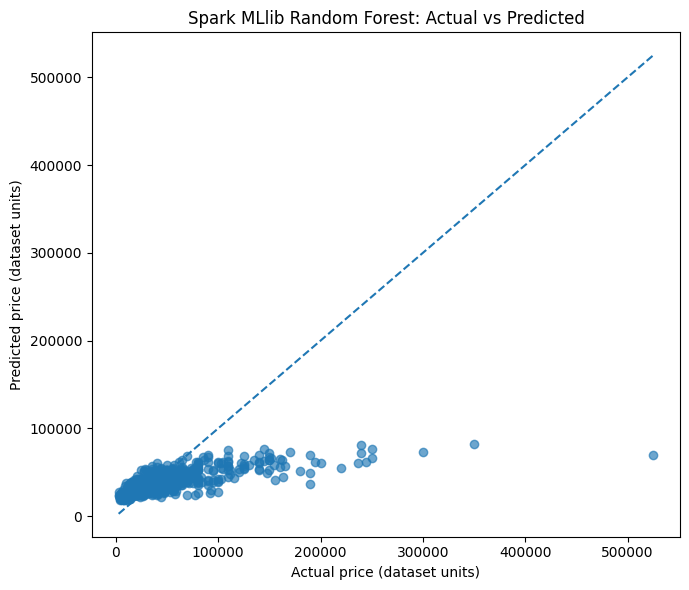

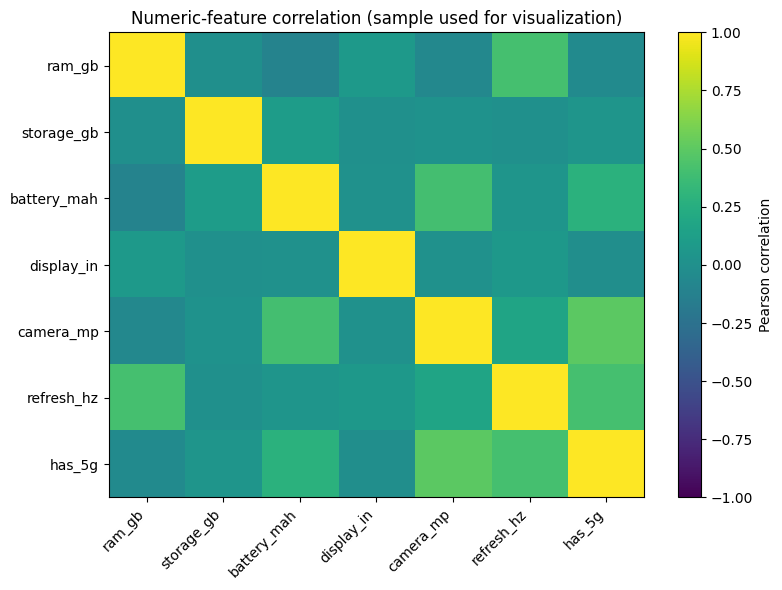

In [ ]:
results = (
    predictions
    .select(F.col("price").alias("actual_price"), F.col("prediction").alias("predicted_price"))
    .withColumn("absolute_error", F.abs(F.col("actual_price") - F.col("predicted_price")))
)
print("Largest absolute errors in the held-out test data:")
display(results.orderBy(F.desc("absolute_error")).limit(15).toPandas())

plot_sample = results.orderBy(F.rand(seed=42)).limit(1000).toPandas()
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(plot_sample["actual_price"], plot_sample["predicted_price"], alpha=0.65)
low = min(plot_sample["actual_price"].min(), plot_sample["predicted_price"].min())
high = max(plot_sample["actual_price"].max(), plot_sample["predicted_price"].max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual price (dataset units)")
plt.ylabel("Predicted price (dataset units)")
plt.title("Spark MLlib Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Correlation heatmap is computed from a small numeric-only sample for visualization.
# Model fitting and cleaning remain Spark-native.
correlation_source = clean.select(*numeric_features).orderBy(F.rand(seed=17)).limit(2500).toPandas()
correlation_matrix = correlation_source.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
plt.title("Numeric-feature correlation (sample used for visualization)")
plt.tight_layout()
plt.show()

## 8. User requirements → Spark MLlib price estimate
`estimate_price()` builds a one-row Spark DataFrame with the same feature schema used in training and sends it through the fitted Spark MLlib pipeline. This prediction is the model's estimated price for the requested specifications; it is not a guarantee of a retailer's current selling price.

In [ ]:
# Build an explicit schema so blank numeric fields remain valid nullable doubles.
request_schema = T.StructType(
    [T.StructField(field, T.DoubleType(), True) for field in numeric_features]
    + [T.StructField(field, T.StringType(), True) for field in categorical_features]
)


def _clean_request_value(value):
    if value is None:
        return None
    if isinstance(value, str) and not value.strip():
        return None
    return value


def request_dataframe(requirements):
    row = {}
    for field in numeric_features:
        value = _clean_request_value(requirements.get(field))
        row[field] = None if value is None else float(value)
    for field in categorical_features:
        value = _clean_request_value(requirements.get(field))
        row[field] = None if value is None else str(value).strip()
    return spark.createDataFrame([row], schema=request_schema)


def estimate_price(requirements):
    """Estimate price with the fitted Spark MLlib pipeline; result uses dataset price units."""
    request_df = request_dataframe(requirements)
    row = price_model.transform(request_df).select("prediction").first()
    value = float(row["prediction"])
    if not (value == value and abs(value) != float("inf")):
        raise ValueError("The Spark model returned a non-finite price estimate.")
    return value


EXAMPLE_REQUIREMENTS = {
    "ram_gb": 8,
    "storage_gb": 256,
    "battery_mah": 5000,
    "display_in": 6.7,
    "camera_mp": 50,
    "refresh_hz": 120,
    "has_5g": 1,
    "brand": None,
    "chipset": None,
    "os": "Android",
}
example_estimate = estimate_price(EXAMPLE_REQUIREMENTS)
print(f"Example requirement price estimate: {example_estimate:,.2f} (dataset price units)")
print("Input requirements:", EXAMPLE_REQUIREMENTS)

Example requirement price estimate: 54,814.31 (dataset price units)
Input requirements: {'ram_gb': 8, 'storage_gb': 256, 'battery_mah': 5000, 'display_in': 6.7, 'camera_mp': 50, 'refresh_hz': 120, 'has_5g': 1, 'brand': None, 'chipset': None, 'os': 'Android'}


## 9. Budget-aware ranked recommendations
The recommender is intentionally a transparent, separate matching heuristic rather than a second ML model. A lower `match_score` means a closer match. The optional budget is a strict filter (`price <= budget`); absent user requirements are ignored.

In [ ]:
NUMERIC_MATCH_WEIGHTS = {
    "ram_gb": 2.0,
    "storage_gb": 1.6,
    "battery_mah": 1.0,
    "display_in": 0.8,
    "camera_mp": 1.0,
    "refresh_hz": 0.8,
    "has_5g": 1.4,
}
CATEGORY_MATCH_WEIGHTS = {"brand": 1.0, "chipset": 1.2, "os": 0.8}

# Robust normalisation ranges are computed once with Spark quantiles (not on a Pandas copy).
numeric_scales = {}
for field in NUMERIC_MATCH_WEIGHTS:
    if field in clean.columns and available_counts.get(field, 0) > 0:
        quantiles = clean.approxQuantile(field, [0.10, 0.90], 0.01)
        if len(quantiles) == 2:
            numeric_scales[field] = max(float(quantiles[1] - quantiles[0]), 1.0)
        else:
            numeric_scales[field] = 1.0


def recommend_phones(requirements, budget=None, top_n=10):
    """Return Spark DataFrame of ranked catalogue matches and a model price estimate."""
    if top_n < 1:
        raise ValueError("top_n must be at least 1")
    estimated = estimate_price(requirements)
    candidates_df = clean
    if budget is not None:
        budget_value = float(budget)
        if budget_value < 0:
            raise ValueError("Budget must be non-negative.")
        candidates_df = candidates_df.filter(F.col("price") <= F.lit(budget_value))

    if candidates_df.limit(1).count() == 0:
        return candidates_df, estimated, "No catalog phones are priced at or below the entered budget."

    score = F.lit(0.0)
    total_weight = 0.0
    for field, weight in NUMERIC_MATCH_WEIGHTS.items():
        target_value = _clean_request_value(requirements.get(field))
        if target_value is None or field not in candidates_df.columns or field not in numeric_scales:
            continue
        target_value = float(target_value)
        scale = float(numeric_scales[field])
        distance = F.least(F.abs(F.col(field) - F.lit(target_value)) / F.lit(scale), F.lit(3.0))
        distance = F.when(F.col(field).isNull(), F.lit(1.5)).otherwise(distance)
        score = score + distance * F.lit(weight)
        total_weight += weight

    for field, weight in CATEGORY_MATCH_WEIGHTS.items():
        target_value = _clean_request_value(requirements.get(field))
        if target_value is None or field not in candidates_df.columns:
            continue
        target_lower = str(target_value).strip().lower()
        matches = F.lower(F.coalesce(F.col(field), F.lit(""))).contains(target_lower)
        penalty = F.when(matches, F.lit(0.0)).otherwise(F.lit(1.0))
        score = score + penalty * F.lit(weight)
        total_weight += weight

    # No supplied specs means all candidates have a neutral match score; price proximity breaks ties.
    score_denominator = max(total_weight, 1.0)
    ranked = (
        candidates_df
        .withColumn("match_score", score / F.lit(score_denominator))
        .withColumn("estimated_price_for_requirement", F.lit(estimated))
        .withColumn("price_gap_from_estimate", F.abs(F.col("price") - F.lit(estimated)))
        .orderBy(F.asc("match_score"), F.asc("price_gap_from_estimate"), F.asc("price"))
    )
    return ranked.limit(int(top_n)), estimated, None


example_recommendations, example_estimate, recommendation_message = recommend_phones(
    EXAMPLE_REQUIREMENTS, budget=None, top_n=10
)
print(f"Predicted price for the example requirements: {example_estimate:,.2f} (dataset price units)")
if recommendation_message:
    print(recommendation_message)
else:
    print("Top recommendations. Lower match_score means a closer match:")
    display(example_recommendations.select(
        "name", "brand", "price", "ram_gb", "storage_gb", "battery_mah",
        "display_in", "camera_mp", "refresh_hz", "has_5g", "chipset", "os",
        "match_score", "price_gap_from_estimate"
    ).toPandas())

Predicted price for the example requirements: 54,814.31 (dataset price units)
Top recommendations. Lower match_score means a closer match:


,name,brand,price,ram_gb,storage_gb,battery_mah,display_in,camera_mp,refresh_hz,has_5g,chipset,os,match_score,price_gap_from_estimate
0,Motorola Moto G Stylus 5G (2024),Motorola,50000.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM6450 Snapdragon 6 Gen 1 (4 nm),Android 14,0.000000,4814.308409
1,Motorola Moto G Stylus 5G (2025),Motorola,50000.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM6475-AB Snapdragon 6 Gen 3 (4 nm),Android 15,0.000000,4814.308409
2,Nothing Phone (2a) Plus,Nothing,38000.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Mediatek Dimensity 7350 Pro (4 nm),"Android 14, Nothing OS 2.6, up to 3 major Andr...",0.000000,16814.308409
3,Oppo A3 (China),Oppo,30000.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM6375 Snapdragon 695 5G (6 nm),"Android 14, ColorOS 14",0.000000,24814.308409
4,Motorola Edge 50,Motorola,29000.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM7450-AB Snapdragon 7 Gen 1 AE (4 nm),"Android 14, up to 2 major Android upgrades",0.000000,25814.308409
5,Motorola Edge 60 Stylus,Motorola,26500.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM7435-AB Snapdragon 7s Gen 2 (4 nm),"Android 15, up to 2 major Android upgrades",0.000000,28314.308409
6,Motorola Moto S50 Neo,Motorola,26500.0,8.0,256.0,5000.0,6.70,50.0,120.0,1.0,Qualcomm SM6375 Snapdragon 6s Gen 3 (6 nm),Android 14,0.000000,28314.308409
7,Vivo V40 SE,Vivo,38000.0,8.0,256.0,5000.0,6.67,50.0,120.0,1.0,Qualcomm Snapdragon 4 Gen 2 (4 nm),"Android 14, Funtouch 14",0.001964,16814.308409
8,Xiaomi Poco F6,Xiaomi,36500.0,8.0,256.0,5000.0,6.67,50.0,120.0,1.0,Qualcomm SM8635 Snapdragon 8s Gen 3 (4 nm),"Android 14, HyperOS",0.001964,18314.308409
9,Vivo Y200 (Asia),Vivo,35000.0,8.0,256.0,5000.0,6.67,50.0,120.0,1.0,Qualcomm SM4450 Snapdragon 4 Gen 2 (4 nm),"Android 14, Funtouch 14",0.001964,19814.308409


## 10. Try a custom requirement and optional budget
This is an optional interactive cell. Press Enter on any spec you want the system to ignore. Values and budget are in the source dataset's price scale; currency conversion is deliberately not performed.

In [ ]:
def _ask_optional_float(prompt):
    text_value = input(prompt).strip()
    if not text_value:
        return None
    try:
        return float(text_value)
    except ValueError:
        print("Invalid number; this requirement will be ignored.")
        return None


def run_interactive_recommendation():
    print("Enter phone requirements; leave fields blank to ignore them.")
    req = {
        "ram_gb": _ask_optional_float("RAM (GB), e.g. 8: "),
        "storage_gb": _ask_optional_float("Storage (GB), e.g. 256: "),
        "battery_mah": _ask_optional_float("Battery (mAh), e.g. 5000: "),
        "display_in": _ask_optional_float("Display size (inches), e.g. 6.7: "),
        "camera_mp": _ask_optional_float("Main camera (MP), e.g. 50: "),
        "refresh_hz": _ask_optional_float("Refresh rate (Hz), e.g. 120: "),
    }
    five_g = input("5G required? [yes/no/blank]: ").strip().lower()
    req["has_5g"] = 1 if five_g in ["yes", "y", "true", "1"] else (0 if five_g in ["no", "n", "false", "0"] else None)
    for field, prompt in [("brand", "Preferred brand (optional): "), ("chipset", "Preferred chipset (optional): "), ("os", "Preferred OS (optional): ")]:
        req[field] = input(prompt).strip() or None
    budget_text = input("Maximum budget in dataset price units (blank for no budget): ").strip()
    budget = None
    if budget_text:
        try:
            budget = float(budget_text)
        except ValueError:
            print("Invalid budget; proceeding without a budget filter.")
    recs, predicted, message = recommend_phones(req, budget=budget, top_n=10)
    print(f"Estimated price: {predicted:,.2f} (dataset price units)")
    if message:
        print(message)
    else:
        display(recs.select("name", "brand", "price", "ram_gb", "storage_gb", "battery_mah", "display_in", "camera_mp", "refresh_hz", "has_5g", "match_score").toPandas())
    return req, predicted, recs

# Uncomment the next line when you want to enter custom requirements interactively.
# custom_requirements, custom_estimate, custom_recommendations = run_interactive_recommendation()
print("Interactive function ready. Uncomment the function call to try your own requirements.")

Interactive function ready. Uncomment the function call to try your own requirements.


## 11. Optional, real Scala GraphX project demonstration
GraphX is a Scala API in Spark, not simply a Python NetworkX graph or a GraphFrames substitute. This section attempts a small catalog-derived graph using `spark-shell` if it exists in the PySpark distribution. It builds vertices for phones, brands, operating systems and (when available) chipsets, then checks graph vertex/edge counts and relationship types. If the runtime lacks `spark-shell`/GraphX or the attempt fails, the output says so; do not describe CO6/GraphX as successfully implemented unless the success marker appears.

To avoid running two Spark drivers simultaneously, this cell stops the Python SparkSession before launching the Scala shell. It should be run at the end of the notebook.

In [ ]:
# Build a small graph from actual catalog rows, keeping only a small sample for the Scala demo.
# A distinct graph vertex is created for each phone/brand/OS/chipset label.
graph_source_rows = (
    clean.select("name", "brand", "os", "chipset")
         .where(F.col("name").isNotNull())
         .orderBy("name")
         .limit(15)
         .collect()
)


def scala_quote(value):
    # JSON quoted strings are compatible with ordinary Scala string literals for this use.
    return json.dumps(str(value), ensure_ascii=True)


def run_graphx_demo(rows):
    try:
        import pyspark
        pyspark_home = str(Path(pyspark.__file__).resolve().parent)
        possible_shells = [
            shutil.which("spark-shell"),
            os.path.join(pyspark_home, "bin", "spark-shell"),
            os.path.join(os.environ.get("SPARK_HOME", ""), "bin", "spark-shell") if os.environ.get("SPARK_HOME") else None,
        ]
        shell = next((p for p in possible_shells if p and os.path.isfile(p)), None)
        if not shell:
            print("GRAPHX STATUS: NOT EXECUTED — this PySpark install does not expose spark-shell.")
            print("The rest of the MLlib notebook is independent of this optional Scala step.")
            return False
        if not rows:
            print("GRAPHX STATUS: NOT EXECUTED — no catalog rows were available to form graph vertices.")
            return False

        vertices = {}
        edges = []
        next_id = 1
        def vertex_id(label):
            nonlocal next_id
            if label not in vertices:
                vertices[label] = next_id
                next_id += 1
            return vertices[label]

        for row in rows:
            phone_label = "Phone: " + (row["name"] or "Unknown")
            phone_id = vertex_id(phone_label)
            for field, prefix, edge_type in [("brand", "Brand: ", "brand"), ("os", "OS: ", "runs_on"), ("chipset", "Chipset: ", "uses_chipset")]:
                raw_value = row[field]
                if raw_value is not None and str(raw_value).strip() and str(raw_value).strip().lower() not in PLACEHOLDERS:
                    related_id = vertex_id(prefix + str(raw_value).strip())
                    edges.append((phone_id, related_id, edge_type))

        if not edges:
            print("GRAPHX STATUS: NOT EXECUTED — no relationships could be built from the available sample.")
            return False

        vertex_literal = ",\n".join(f"({vid}L, {scala_quote(label)})" for label, vid in vertices.items())
        edge_literal = ",\n".join(f"Edge({src}L, {dst}L, {scala_quote(edge_type)})" for src, dst, edge_type in edges)
        scala_program = f"""import org.apache.spark.graphx._
val smartSpecVertices = sc.parallelize(Seq(
{vertex_literal}
))
val smartSpecEdges = sc.parallelize(Seq(
{edge_literal}
))
val smartSpecGraph = Graph(smartSpecVertices, smartSpecEdges)
println("SMARTSPEC_GRAPHX_VERTICES=" + smartSpecGraph.vertices.count())
println("SMARTSPEC_GRAPHX_EDGES=" + smartSpecGraph.edges.count())
println("SMARTSPEC_GRAPHX_BRAND_LINKS=" + smartSpecGraph.triplets.filter(_.attr == "brand").count())
println("SMARTSPEC_GRAPHX_OS_LINKS=" + smartSpecGraph.triplets.filter(_.attr == "runs_on").count())
println("SMARTSPEC_GRAPHX_SUCCESS")
System.exit(0)
"""
        script_path = os.path.join(tempfile.gettempdir(), "smartspec_graphx_demo.scala")
        with open(script_path, "w", encoding="utf-8") as handle:
            handle.write(scala_program)

        # Stop PySpark's context before launching a separate Scala Spark shell process.
        try:
            spark.stop()
        except Exception:
            pass
        print("Launching the Scala GraphX demonstration. It can take a short time to start the shell...")
        completed = subprocess.run(
            [shell, "--master", "local[*]", "--conf", "spark.ui.enabled=false", "-i", script_path],
            capture_output=True, text=True, timeout=150
        )
        output = (completed.stdout or "") + "\n" + (completed.stderr or "")
        success = "SMARTSPEC_GRAPHX_SUCCESS" in output
        for line in output.splitlines():
            if "SMARTSPEC_GRAPHX_" in line or "error:" in line.lower() or "exception" in line.lower():
                print(line[-500:])
        if success:
            print("GRAPHX STATUS: SUCCESS — the Scala GraphX sample created and queried the graph.")
            return True
        print(f"GRAPHX STATUS: NOT VERIFIED — spark-shell exited with code {completed.returncode}; inspect the messages above.")
        print("Do not claim GraphX success in the report unless the success marker is present.")
        return False
    except subprocess.TimeoutExpired:
        print("GRAPHX STATUS: NOT VERIFIED — Scala spark-shell exceeded the 150-second timeout.")
        return False
    except Exception as exc:
        print(f"GRAPHX STATUS: NOT VERIFIED — {type(exc).__name__}: {exc}")
        return False

GRAPHX_EXECUTED_SUCCESSFULLY = run_graphx_demo(graph_source_rows)

Launching the Scala GraphX demonstration. It can take a short time to start the shell...
GRAPHX STATUS: NOT VERIFIED — spark-shell exited with code 0; inspect the messages above.
Do not claim GraphX success in the report unless the success marker is present.


## 12. Final implementation summary and interpretation
Use outputs from this run in your report; do not copy example metric values from earlier scikit-learn screenshots.

- **Model backend:** Apache Spark MLlib `RandomForestRegressor` in a Spark `Pipeline`.
- **Data processing:** Spark DataFrames and Spark SQL; the RDD cell demonstrates a true transformation/action.
- **Evaluation:** actual held-out MAE, RMSE and R² printed by the model cell.
- **Recommendation:** separate, explainable weighted similarity ranking with an optional strict price filter.
- **GraphX:** see the explicit success/status output from the preceding Scala cell. Only claim GraphX was executed if `GRAPHX_EXECUTED_SUCCESSFULLY` is `True`.
- **Limitations:** price quality/currency/market date depends on the supplied dataset; multi-capacity strings are reduced to the first listed capacity; recommendation weights are heuristics, not trained from purchase history; Colab local mode is not a distributed multi-node cluster.

### Official references
- Apache Spark 4.0.1 ML programming guide: https://spark.apache.org/docs/4.0.1/ml-guide.html
- Apache Spark 4.0.1 ML feature transformers: https://spark.apache.org/docs/4.0.1/ml-features.html
- Apache Spark 4.0.1 SQL guide: https://spark.apache.org/docs/4.0.1/sql-programming-guide.html
- Apache Spark 4.0.1 RDD programming guide: https://spark.apache.org/docs/4.0.1/rdd-programming-guide.html
- Apache Spark 4.0.1 GraphX programming guide: https://spark.apache.org/docs/4.0.1/graphx-programming-guide.html
- Dataset source URL referenced in the existing project materials (verify source license and currency before submission): https://www.kaggle.com/datasets/utsh0dey/global-mobile-phone-specifications-and-prices